# UNISOLAR Dataset Exploration

## Project
Solar Power Forecasting using Hybrid XGBoost-LSTM

## Dataset
UNISOLAR Solar Power Generation Dataset

## Mục tiêu
Notebook này thực hiện phân tích dữ liệu khám phá (EDA) trên bộ dữ liệu UNISOLAR
nhằm phục vụ việc dự báo ngắn hạn sản lượng điện mặt trời.


## 1. Import thư viện

In [17]:
import os
import glob
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.preprocessing import StandardScaler

from xgboost import XGBRegressor

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

pd.set_option("display.max_columns", None)

## 2. Load file

In [18]:
def find_file(filename):
    files = glob.glob(
        f"/kaggle/input/**/{filename}",
        recursive=True
    )
    
    if len(files) == 0:
        raise FileNotFoundError(
            f"Không tìm thấy file: {filename}"
        )
    
    print(filename, "->", files[0])
    return files[0]


solar_path = find_file(
    "Solar_Energy_Generation.csv"
)

site_path = find_file(
    "Solar_Site_Details.csv"
)

monthly_path = find_file(
    "Monthly_Summary_Solar.csv"
)

irradiance_path = find_file(
    "Solar_Irradiance.csv"
)

Solar_Energy_Generation.csv -> /kaggle/input/datasets/cdaclab/unisolar/unisolar/Solar_Energy_Generation.csv
Solar_Site_Details.csv -> /kaggle/input/datasets/cdaclab/unisolar/unisolar/Solar_Site_Details.csv
Monthly_Summary_Solar.csv -> /kaggle/input/datasets/cdaclab/unisolar/unisolar/Monthly_Summary_Solar.csv
Solar_Irradiance.csv -> /kaggle/input/datasets/maiemm/solar-irradiance/Solar_Irradiance.csv


In [19]:
weather_files = glob.glob(
    "/kaggle/input/**/Weather_Data_*all.csv",
    recursive=True
)

print(weather_files)

weather_path = weather_files[0]

['/kaggle/input/datasets/cdaclab/unisolar/unisolar/Weather_Data_reordered_all.csv']


## 3. Đọc dữ liệu

In [20]:
solar = pd.read_csv(solar_path)

weather = pd.read_csv(weather_path)

site = pd.read_csv(site_path)

monthly = pd.read_csv(monthly_path)

irradiance = pd.read_csv(irradiance_path)

In [21]:
print("Solar:", solar.shape)
print("Weather:", weather.shape)
print("Site:", site.shape)
print("Monthly:", monthly.shape)
print("Irradiance:", irradiance.shape)

Solar: (2731946, 4)
Weather: (371769, 8)
Site: (42, 10)
Monthly: (1176, 7)
Irradiance: (102360, 4)


## 4. Xem cấu trúc dữ liệu

In [22]:
datasets = {
    "Solar": solar,
    "Weather": weather,
    "Site": site,
    "Monthly": monthly,
    "Irradiance": irradiance
}

for name, df in datasets.items():
    print("\n========================")
    print(name)
    print("========================")
    
    print("Shape:", df.shape)
    print("Columns:")
    print(df.columns.tolist())
    
    display(df.head())


Solar
Shape: (2731946, 4)
Columns:
['CampusKey', 'SiteKey', 'Timestamp', 'SolarGeneration']


,CampusKey,SiteKey,Timestamp,SolarGeneration
0,2,1,2020-01-01 00:15:00,NaN
1,2,1,2020-01-01 00:30:00,NaN
2,2,1,2020-01-01 00:45:00,NaN
3,2,1,2020-01-01 01:00:00,NaN
4,2,1,2020-01-01 01:15:00,NaN



Weather
Shape: (371769, 8)
Columns:
['CampusKey', 'Timestamp', 'ApparentTemperature', 'AirTemperature', 'DewPointTemperature', 'RelativeHumidity', 'WindSpeed', 'WindDirection']


,CampusKey,Timestamp,ApparentTemperature,AirTemperature,DewPointTemperature,RelativeHumidity,WindSpeed,WindDirection
0,1,2020-01-01 00:00:00,13.666667,13.880000,8.960000,72.400000,0.000000,188.133333
1,1,2020-01-01 00:15:00,13.206667,13.666667,9.040000,73.466667,1.200000,203.866667
2,1,2020-01-01 00:30:00,12.840000,13.553333,9.053333,74.000000,2.520000,222.800000
3,1,2020-01-01 00:45:00,12.113333,13.506667,9.100000,74.466667,5.986667,231.133333
4,1,2020-01-01 01:00:00,11.946667,13.260000,9.266667,76.533333,5.946667,247.866667



Site
Shape: (42, 10)
Columns:
['CampusKey', 'SiteKey', 'kWp', 'Number of panels', 'Panel', 'Inverter', 'Optimizers', 'Metric', 'lat', 'Lon']


,CampusKey,SiteKey,kWp,Number of panels,Panel,Inverter,Optimizers,Metric,lat,Lon
0,2,1,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679
1,2,2,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679
2,2,3,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679
3,2,4,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679
4,2,5,NaN,NaN,NaN,NaN,NaN,NaN,-36.111209,146.848679



Monthly
Shape: (1176, 7)
Columns:
['SiteKey', 'Year', 'Month', 'DataStatus', 'AverageSolarGeneration', 'MaxSolarGeneration', 'MinSolarGeneration']


,SiteKey,Year,Month,DataStatus,AverageSolarGeneration,MaxSolarGeneration,MinSolarGeneration
0,1,2020,January,True,10.157125,21.778,0.101
1,2,2020,January,True,8.536875,18.553,0.100
2,3,2020,January,True,6.309834,13.322,0.103
3,4,2020,January,False,NaN,NaN,NaN
4,5,2020,January,False,NaN,NaN,NaN



Irradiance
Shape: (102360, 4)
Columns:
['CloudOpacity', 'Ghi', 'Timestamp_UTC', 'Campus']


,CloudOpacity,Ghi,Timestamp_UTC,Campus
0,15.5,823,2019-12-31 00:00:00,Bundoora
1,0.0,1063,2019-12-31 01:00:00,Bundoora
2,0.0,1090,2019-12-31 02:00:00,Bundoora
3,0.0,1049,2019-12-31 03:00:00,Bundoora
4,0.0,948,2019-12-31 04:00:00,Bundoora


## 5. Chuyển timestamp

In [23]:
#solar and weather
solar["Timestamp"] = pd.to_datetime(
    solar["Timestamp"],
    errors="coerce"
)

weather["Timestamp"] = pd.to_datetime(
    weather["Timestamp"],
    errors="coerce"
)

In [24]:
#irradiance
irradiance["Timestamp_UTC"] = pd.to_datetime(
    irradiance["Timestamp_UTC"],
    errors="coerce",
    utc=True
)
irradiance["Timestamp"] = (
    irradiance["Timestamp_UTC"]
    .dt.tz_convert("Australia/Melbourne")
    .dt.tz_localize(None)
)
irradiance[
    ["Timestamp_UTC", "Timestamp", "Ghi"]
].head()

,Timestamp_UTC,Timestamp,Ghi
0,2019-12-31 00:00:00+00:00,2019-12-31 11:00:00,823
1,2019-12-31 01:00:00+00:00,2019-12-31 12:00:00,1063
2,2019-12-31 02:00:00+00:00,2019-12-31 13:00:00,1090
3,2019-12-31 03:00:00+00:00,2019-12-31 14:00:00,1049
4,2019-12-31 04:00:00+00:00,2019-12-31 15:00:00,948


In [27]:
print("Solar dtype:")
print(solar["Timestamp"].dtype)

print("\nWeather dtype:")
print(weather["Timestamp"].dtype)

print("\nIrradiance dtype:")
print(irradiance["Timestamp_UTC"].dtype)

Solar dtype:
datetime64[ns]

Weather dtype:
datetime64[ns]

Irradiance dtype:
datetime64[ns, UTC]


In [28]:
print("NaT Solar:",
      solar["Timestamp"].isna().sum())

print("NaT Weather:",
      weather["Timestamp"].isna().sum())

print("NaT Irradiance:",
      irradiance["Timestamp_UTC"].isna().sum())

NaT Solar: 0
NaT Weather: 0
NaT Irradiance: 0


## 6. Kiểm tra missing

In [25]:
def missing_summary(df):
    
    result = pd.DataFrame({
        "Missing": df.isna().sum(),
        "Missing_Percent":
            df.isna().mean() * 100
    })
    
    return result.sort_values(
        "Missing_Percent",
        ascending=False
    )


display(missing_summary(solar))
display(missing_summary(weather))
display(missing_summary(irradiance))
display(missing_summary(site))
display(missing_summary(monthly))

,Missing,Missing_Percent
SolarGeneration,1536301,56.234677
CampusKey,0,0.000000
SiteKey,0,0.000000
Timestamp,0,0.000000


,Missing,Missing_Percent
WindSpeed,162890,43.814842
WindDirection,162890,43.814842
AirTemperature,107113,28.811708
ApparentTemperature,107113,28.811708
RelativeHumidity,107113,28.811708
DewPointTemperature,107113,28.811708
CampusKey,0,0.000000
Timestamp,0,0.000000


,Missing,Missing_Percent
CloudOpacity,0,0.0
Ghi,0,0.0
Timestamp_UTC,0,0.0
Campus,0,0.0
Timestamp,0,0.0


,Missing,Missing_Percent
Optimizers,19,45.238095
kWp,17,40.476190
Inverter,17,40.476190
Metric,17,40.476190
Panel,17,40.476190
Number of panels,17,40.476190
SiteKey,0,0.000000
CampusKey,0,0.000000
lat,0,0.000000
Lon,0,0.000000


,Missing,Missing_Percent
MinSolarGeneration,200,17.006803
MaxSolarGeneration,200,17.006803
AverageSolarGeneration,200,17.006803
Month,0,0.000000
Year,0,0.000000
SiteKey,0,0.000000
DataStatus,0,0.000000


## 7. kiểm tra duplicate

In [26]:
# 1. Solar Generation
print("Solar duplicate:")
print(
    solar.duplicated(
        subset=["CampusKey", "SiteKey", "Timestamp"]
    ).sum()
)

# 2. Weather
print("Weather duplicate:")
print(
    weather.duplicated(
        subset=["CampusKey", "Timestamp"]
    ).sum()
)

# 3. Solar Site Details
print("Site duplicate:")
print(
    site.duplicated(
        subset=["CampusKey", "SiteKey"]
    ).sum()
)

# 4. Monthly Summary
print("Monthly duplicate:")
print(
    monthly.duplicated(
        subset=["SiteKey", "Year", "Month"]
    ).sum()
)

# 5. Solar Irradiance
print("Irradiance duplicate:")
print(
    irradiance.duplicated(
        subset=["Campus", "Timestamp_UTC"]
    ).sum()
)

Solar duplicate:
0
Weather duplicate:
0
Site duplicate:
0
Monthly duplicate:
0
Irradiance duplicate:
0


## 8. Chuẩn hóa SiteKey/CampusKey

In [29]:
solar["CampusKey"] = (
    solar["CampusKey"]
    .astype("int16")
)

solar["SiteKey"] = (
    solar["SiteKey"]
    .astype("int16")
)

weather["CampusKey"] = (
    weather["CampusKey"]
    .astype("int16")
)

site["CampusKey"] = (
    site["CampusKey"]
    .astype("int16")
)

site["SiteKey"] = (
    site["SiteKey"]
    .astype("int16")
)

monthly["SiteKey"] = (
    monthly["SiteKey"]
    .astype("int16")
)

In [30]:
# Tạo một ID duy nhất cho từng hệ PV:
solar["SiteID"] = (
    solar["CampusKey"].astype(str)
    + "_"
    + solar["SiteKey"].astype(str)
)

site["SiteID"] = (
    site["CampusKey"].astype(str)
    + "_"
    + site["SiteKey"].astype(str)
)

## 9. Kiểm tra số campus và số site

In [31]:
print(
    "Số Campus trong Solar:",
    solar["CampusKey"].nunique()
)

print(
    "Số Site:",
    solar["SiteID"].nunique()
)

print(
    "\nCampusKey:"
)

print(
    sorted(
        solar["CampusKey"].unique()
    )
)

Số Campus trong Solar: 5
Số Site: 42

CampusKey:
[np.int16(1), np.int16(2), np.int16(3), np.int16(4), np.int16(5)]


## 10. Xem thông tin từng Campus

In [32]:
campus_info = (
    site
    .groupby("CampusKey")
    .agg(
        Number_of_Sites=(
            "SiteKey",
            "nunique"
        ),
        Latitude=(
            "lat",
            "median"
        ),
        Longitude=(
            "Lon",
            "median"
        )
    )
    .reset_index()
)

campus_info

,CampusKey,Number_of_Sites,Latitude,Longitude
0,1,27,-37.718287,145.050975
1,2,5,-36.111209,146.848679
2,3,8,-36.778858,144.301232
3,4,1,-34.205289,142.166556
4,5,1,-36.380319,145.406290


## 11. Xem campus trong Irradiance

In [33]:
irradiance[
    "Campus"
].value_counts()


Campus
Bundoora      20472
Bendigo       20472
Wodonga       20472
Mildura       20472
Shepparton    20472
Name: count, dtype: int64

In [34]:
print(
    irradiance["Campus"]
    .unique()
)

['Bundoora' 'Bendigo' 'Wodonga' 'Mildura' 'Shepparton']


## 12. Kiểm tra khoảng thời gian

In [35]:
#solar
solar_range = (
    solar
    .groupby("CampusKey")["Timestamp"]
    .agg(
        Start="min",
        End="max",
        Rows="count"
    )
)

solar_range

,Start,End,Rows
CampusKey,,,
1,2020-01-01 00:15:00,2022-04-23 23:45:00,1720219
2,2020-01-01 00:15:00,2022-04-23 23:45:00,332387
3,2020-01-01 00:15:00,2022-04-23 23:45:00,520702
4,2020-01-01 00:15:00,2022-04-23 23:45:00,79319
5,2020-01-01 00:15:00,2022-04-23 23:45:00,79319


In [36]:
#weather
weather_range = (
    weather
    .groupby("CampusKey")["Timestamp"]
    .agg(
        Start="min",
        End="max",
        Rows="count"
    )
)

weather_range

,Start,End,Rows
CampusKey,,,
1,2020-01-01 00:00:00,2022-04-23 22:00:00,81017
2,2020-01-01 00:00:00,2022-04-23 22:00:00,81017
3,2020-01-01 00:00:00,2022-04-23 22:00:00,81017
4,2020-01-01 00:00:00,2022-04-23 22:00:00,81017
5,2020-12-13 01:00:00,2022-04-23 22:00:00,47701


In [37]:
#irradiance
irradiance_range = (
    irradiance
    .groupby("Campus")["Timestamp_UTC"]
    .agg(
        Start="min",
        End="max",
        Rows="count"
    )
)

irradiance_range

,Start,End,Rows
Campus,,,
Bendigo,2019-12-31 00:00:00+00:00,2022-05-01 23:00:00+00:00,20472
Bundoora,2019-12-31 00:00:00+00:00,2022-05-01 23:00:00+00:00,20472
Mildura,2019-12-31 00:00:00+00:00,2022-05-01 23:00:00+00:00,20472
Shepparton,2019-12-31 00:00:00+00:00,2022-05-01 23:00:00+00:00,20472
Wodonga,2019-12-31 00:00:00+00:00,2022-05-01 23:00:00+00:00,20472


## 13. Tạo mapping CampusKey → Campus

In [38]:
campus_map = {
    1: "Bundoora",
    2: "Wodonga",
    3: "Bendigo",
    4: "Mildura",
    5: "Shepparton"
}

solar["Campus"] = solar["CampusKey"].map(campus_map)
weather["Campus"] = weather["CampusKey"].map(campus_map)
site["Campus"] = site["CampusKey"].map(campus_map)

## 14. Kiểm tra mapping

In [39]:
print(solar[
    ["CampusKey", "Campus"]
].drop_duplicates().sort_values("CampusKey"))

         CampusKey      Campus
853089           1    Bundoora
0                2     Wodonga
332387           3     Bendigo
2573308          4     Mildura
2652627          5  Shepparton


In [40]:
print("Solar campuses:")
print(sorted(solar["Campus"].dropna().unique()))

print("\nIrradiance campuses:")
print(sorted(irradiance["Campus"].dropna().unique()))

Solar campuses:
['Bendigo', 'Bundoora', 'Mildura', 'Shepparton', 'Wodonga']

Irradiance campuses:
['Bendigo', 'Bundoora', 'Mildura', 'Shepparton', 'Wodonga']


## 15.  Thêm metadata site vào Solar

In [41]:
site_meta = site[
    [
        "CampusKey",
        "SiteKey",
        "kWp",
        "Number of panels",
        "lat",
        "Lon"
    ]
].copy()

In [42]:
#merge
solar = solar.merge(
    site_meta,
    on=["CampusKey", "SiteKey"],
    how="left",
    validate="many_to_one"
)

In [43]:
solar.head()

,CampusKey,SiteKey,Timestamp,SolarGeneration,SiteID,Campus,kWp,Number of panels,lat,Lon
0,2,1,2020-01-01 00:15:00,NaN,2_1,Wodonga,NaN,NaN,-36.111209,146.848679
1,2,1,2020-01-01 00:30:00,NaN,2_1,Wodonga,NaN,NaN,-36.111209,146.848679
2,2,1,2020-01-01 00:45:00,NaN,2_1,Wodonga,NaN,NaN,-36.111209,146.848679
3,2,1,2020-01-01 01:00:00,NaN,2_1,Wodonga,NaN,NaN,-36.111209,146.848679
4,2,1,2020-01-01 01:15:00,NaN,2_1,Wodonga,NaN,NaN,-36.111209,146.848679


## 16. Kiểm tra merge metadata

In [44]:
print("Solar shape:", solar.shape)

print("\nMissing metadata:")
print(
    solar[
        ["kWp", "Number of panels", "lat", "Lon"]
    ].isna().sum()
)

Solar shape: (2731946, 10)

Missing metadata:
kWp                 1132078
Number of panels    1132078
lat                       0
Lon                       0
dtype: int64


## 17. kiểm tra một ngày Solar

In [46]:
campus1_sites = (
    site.loc[
        site["CampusKey"] == 1,
        "SiteKey"
    ]
    .sort_values()
    .tolist()
)

print(campus1_sites)

[14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]


In [47]:
chosen_campus = 1
chosen_site = campus1_sites[0]

print("Campus:", chosen_campus)
print("Site:", chosen_site)

Campus: 1
Site: 14


In [49]:
temp = solar[
    (solar["CampusKey"] == chosen_campus) &
    (solar["SiteKey"] == chosen_site)
].copy()

print("Số dòng:", len(temp))
print("Ngày bắt đầu:", temp["Timestamp"].min())
print("Ngày kết thúc:", temp["Timestamp"].max())

Số dòng: 63964
Ngày bắt đầu: 2020-06-14 00:15:00
Ngày kết thúc: 2022-04-23 23:45:00


In [50]:
#ngày có nhiều giá trị SolarGeneration hợp lệ nhất
daily_count = (
    temp
    .dropna(subset=["SolarGeneration"])
    .groupby(temp["Timestamp"].dt.date)
    ["SolarGeneration"]
    .count()
)

sample_date = daily_count.idxmax()

print("Ngày được chọn:", sample_date)
print("Số điểm dữ liệu hợp lệ:", daily_count.max())

Ngày được chọn: 2020-12-28
Số điểm dữ liệu hợp lệ: 58


In [51]:
sample_day = temp[
    temp["Timestamp"].dt.date == sample_date
][
    ["Timestamp", "SolarGeneration"]
]

sample_day

,Timestamp,SolarGeneration
871566,2020-12-28 00:15:00,NaN
871567,2020-12-28 00:30:00,NaN
871568,2020-12-28 00:45:00,NaN
871569,2020-12-28 01:00:00,NaN
871570,2020-12-28 01:15:00,NaN
...,...,...
871656,2020-12-28 22:45:00,NaN
871657,2020-12-28 23:00:00,NaN
871658,2020-12-28 23:15:00,NaN
871659,2020-12-28 23:30:00,NaN


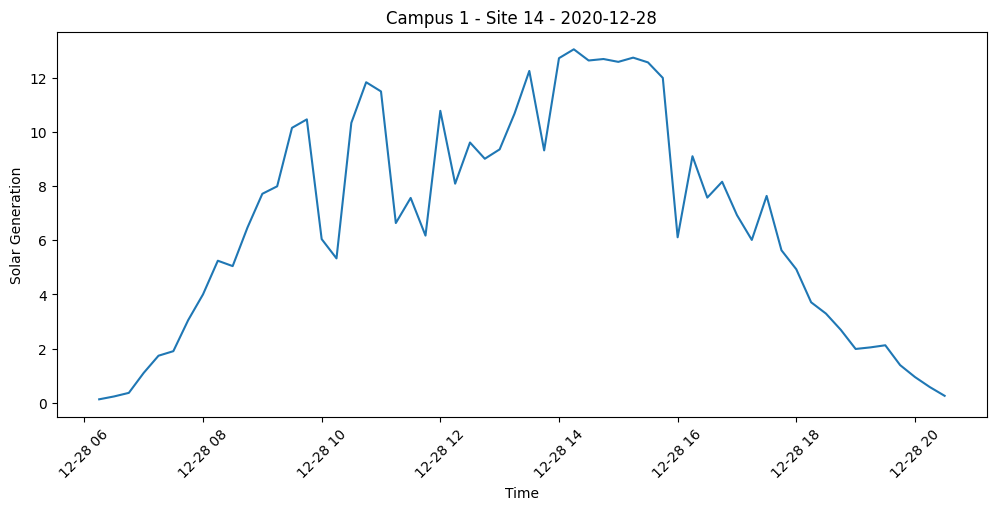

In [52]:
plt.figure(figsize=(12, 5))

plt.plot(
    sample_day["Timestamp"],
    sample_day["SolarGeneration"]
)

plt.xlabel("Time")
plt.ylabel("Solar Generation")
plt.title(
    f"Campus {chosen_campus} - Site {chosen_site} - {sample_date}"
)

plt.xticks(rotation=45)
plt.show()

##  18. thử chuyển local → UTC

In [53]:
test_time = pd.Timestamp(
    "2020-12-28 14:00:00",
    tz="Australia/Melbourne"
)

print("Local time:", test_time)
print("UTC time:", test_time.tz_convert("UTC"))

Local time: 2020-12-28 14:00:00+11:00
UTC time: 2020-12-28 03:00:00+00:00


In [54]:
#kiểm tra GHI Bundoora
check_ghi = irradiance[
    (irradiance["Campus"] == "Bundoora") &
    (irradiance["Timestamp_UTC"] >= pd.Timestamp(
        "2020-12-28 02:00:00",
        tz="UTC"
    )) &
    (irradiance["Timestamp_UTC"] <= pd.Timestamp(
        "2020-12-28 04:00:00",
        tz="UTC"
    ))
]

check_ghi[
    ["Timestamp_UTC", "Ghi", "CloudOpacity"]
]

,Timestamp_UTC,Ghi,CloudOpacity
8714,2020-12-28 02:00:00+00:00,968,10.8
8715,2020-12-28 03:00:00+00:00,848,18.6
8716,2020-12-28 04:00:00+00:00,883,6.0


## 19. Giữ lại timestamp gốc

In [56]:
solar["Timestamp_Local"] = solar["Timestamp"]
weather["Timestamp_Local"] = weather["Timestamp"]

## 20. Chuyển Solar sang UTC

In [57]:
solar["Timestamp_UTC"] = (
    solar["Timestamp_Local"]
    .dt.tz_localize(
        "Australia/Melbourne",
        ambiguous="NaT",
        nonexistent="shift_forward"
    )
    .dt.tz_convert("UTC")
)

## 21. Chuyển Weather sang UTC

In [58]:
weather["Timestamp_UTC"] = (
    weather["Timestamp_Local"]
    .dt.tz_localize(
        "Australia/Melbourne",
        ambiguous="NaT",
        nonexistent="shift_forward"
    )
    .dt.tz_convert("UTC")
)

## 22. Kiểm tra có bao nhiêu NaT do DST

In [59]:
print(
    "Solar UTC NaT:",
    solar["Timestamp_UTC"].isna().sum()
)

print(
    "Weather UTC NaT:",
    weather["Timestamp_UTC"].isna().sum()
)

Solar UTC NaT: 388
Weather UTC NaT: 56


## 23. Kiểm tra ví dụ 28/12/2020

In [60]:
check_solar = solar[
    (solar["CampusKey"] == 1) &
    (solar["SiteKey"] == 14) &
    (
        solar["Timestamp_Local"]
        == pd.Timestamp("2020-12-28 14:00:00")
    )
][
    [
        "Timestamp_Local",
        "Timestamp_UTC",
        "SolarGeneration"
    ]
]

check_solar

,Timestamp_Local,Timestamp_UTC,SolarGeneration
871621,2020-12-28 14:00:00,2020-12-28 03:00:00+00:00,12.746094


## 24. Kiểm tra Solar và Irradiance cùng timestamp

In [61]:
check_compare = check_solar.merge(
    irradiance[
        irradiance["Campus"] == "Bundoora"
    ][
        [
            "Timestamp_UTC",
            "Ghi",
            "CloudOpacity"
        ]
    ],
    on="Timestamp_UTC",
    how="left"
)

check_compare

,Timestamp_Local,Timestamp_UTC,SolarGeneration,Ghi,CloudOpacity
0,2020-12-28 14:00:00,2020-12-28 03:00:00+00:00,12.746094,848,18.6
